In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Loading the cleaned delivery data
project_path = os.path.dirname(os.getcwd())
data_path = os.path.join(project_path, "data")

df = pd.read_csv(os.path.join(data_path, "deliveries_clean.csv"))

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (295732, 23)


C:\Users\sw\AppData\Local\Temp\ipykernel_7836\4099710330.py:10: DtypeWarning: Columns (0: season) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(os.path.join(data_path, "deliveries_clean.csv"))


,match_id,innings,over,delivery_number,batting_team,batter,bowler,runs_batter,runs_total,wides,...,penalty,is_legal_delivery,bowler_runs,balls_faced,total_wickets,bowler_wickets,date,season,venue,city
0,1082591,1,0,1,Sunrisers Hyderabad,DA Warner,TS Mills,0,0,0,...,0,1,0,1,0,0,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad
1,1082591,1,0,2,Sunrisers Hyderabad,DA Warner,TS Mills,0,0,0,...,0,1,0,1,0,0,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad
2,1082591,1,0,3,Sunrisers Hyderabad,DA Warner,TS Mills,4,4,0,...,0,1,4,1,0,0,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad
3,1082591,1,0,4,Sunrisers Hyderabad,DA Warner,TS Mills,0,0,0,...,0,1,0,1,0,0,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad
4,1082591,1,0,5,Sunrisers Hyderabad,DA Warner,TS Mills,0,2,2,...,0,0,2,0,0,0,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad


In [2]:
# Grouping deliveries by bowler to calculate performance
bowling_stats = df.groupby("bowler").agg(
    runs_conceded=("bowler_runs", "sum"),
    wickets=("bowler_wickets", "sum"),
    legal_balls=("is_legal_delivery", "sum"),
    matches_played=("match_id", "nunique")
).reset_index()

# Calculating overs and economy rate
bowling_stats["overs"] = (
    bowling_stats["legal_balls"] / 6
).round(2)

bowling_stats["economy"] = (
    bowling_stats["runs_conceded"] /
    (bowling_stats["legal_balls"] / 6).replace(0, np.nan)
).round(2)

bowling_stats = bowling_stats.sort_values(
    "wickets", ascending=False
)

bowling_stats.head(15)

,bowler,runs_conceded,wickets,legal_balls,matches_played,overs,economy
569,YS Chahal,5417,233,4037,184,672.83,8.05
76,B Kumar,5913,226,4600,206,766.67,7.71
480,SP Narine,5273,209,4660,200,776.67,6.79
374,PP Chawla,5108,192,3850,191,641.67,7.96
213,JJ Bumrah,4469,190,3653,158,608.83,7.34
386,R Ashwin,5652,187,4710,217,785.00,7.20
131,DJ Bravo,4360,183,3120,158,520.00,8.38
405,RA Jadeja,5465,180,4254,237,709.00,7.71
432,Rashid Khan,4297,179,3543,153,590.50,7.28
8,A Mishra,4145,174,3371,162,561.83,7.38


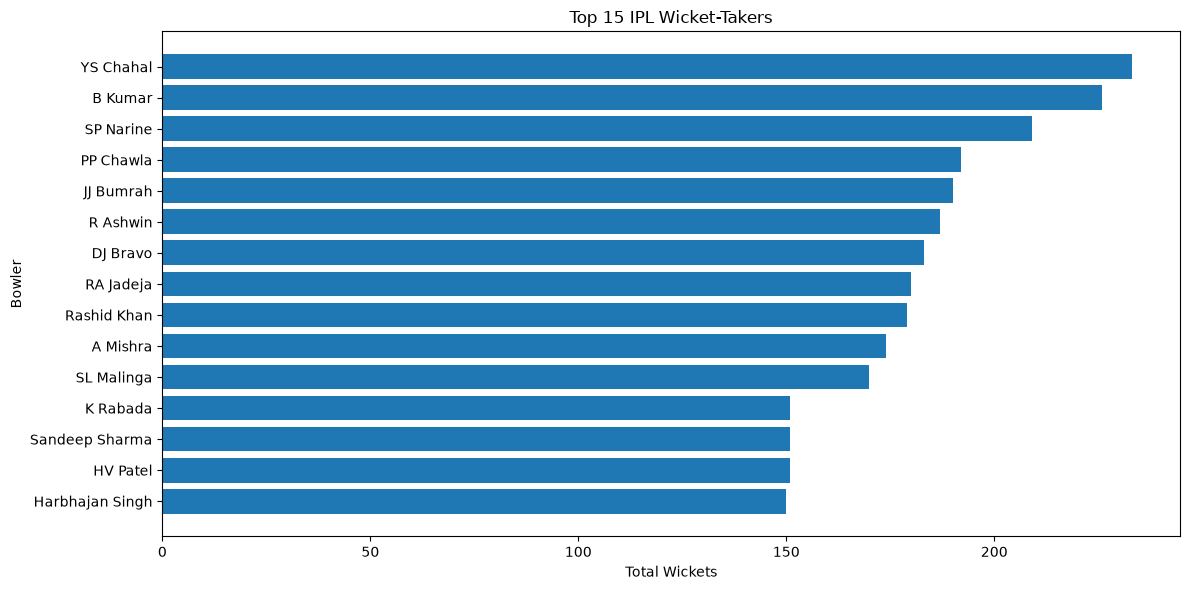

In [3]:
# Finding the 15 bowlers with the most wickets
top_wicket_takers = bowling_stats.head(15)

plt.figure(figsize=(12, 6))

plt.barh(
    top_wicket_takers["bowler"],
    top_wicket_takers["wickets"]
)

plt.title("Top 15 IPL Wicket-Takers")
plt.xlabel("Total Wickets")
plt.ylabel("Bowler")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [4]:
# Filtering bowlers with a reasonable number of legal balls
regular_bowlers = bowling_stats[
    bowling_stats["legal_balls"] >= 300
].copy()

best_economy = regular_bowlers.sort_values(
    "economy", ascending=True
).head(15)

best_economy[[
    "bowler", "matches_played", "legal_balls",
    "runs_conceded", "wickets", "economy"
]]

,bowler,matches_played,legal_balls,runs_conceded,wickets,economy
7,A Kumble,42,965,1058,45,6.58
161,GD McGrath,14,324,357,12,6.61
285,M Muralitharan,66,1528,1706,64,6.70
409,RE van der Merwe,21,443,498,21,6.74
480,SP Narine,200,4660,5273,209,6.79
142,DL Vettori,34,777,879,28,6.79
200,J Yadav,20,390,445,8,6.85
194,J Botha,34,694,800,25,6.92
27,AD Mascarenhas,13,308,356,19,6.94
151,DW Steyn,95,2182,2523,97,6.94


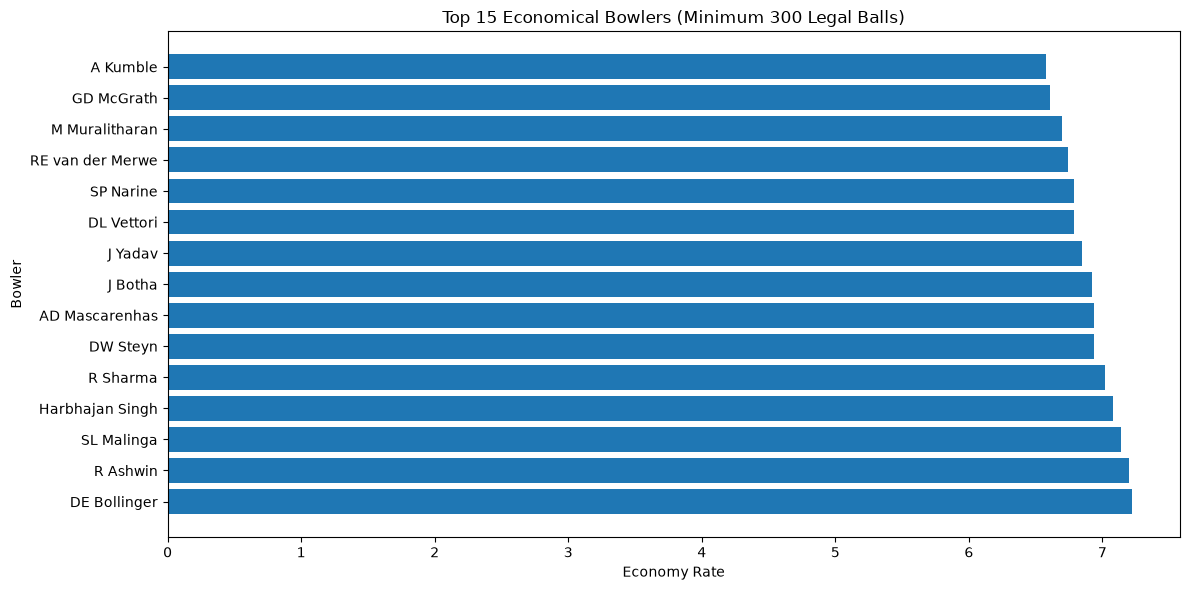

In [5]:
plt.figure(figsize=(12, 6))

plt.barh(
    best_economy["bowler"],
    best_economy["economy"]
)

plt.title("Top 15 Economical Bowlers (Minimum 300 Legal Balls)")
plt.xlabel("Economy Rate")
plt.ylabel("Bowler")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [6]:
# Comparing wicket-taking performance across matches
bowling_stats["wickets_per_match"] = (
    bowling_stats["wickets"] /
    bowling_stats["matches_played"]
).round(2)

consistent_bowlers = bowling_stats[
    bowling_stats["matches_played"] >= 30
].sort_values(
    "wickets_per_match", ascending=False
).head(15)

consistent_bowlers[[
    "bowler", "matches_played", "wickets",
    "wickets_per_match", "economy"
]]

,bowler,matches_played,wickets,wickets_per_match,economy
232,K Rabada,101,151,1.50,8.79
287,M Pathirana,33,47,1.42,8.66
34,AJ Tye,30,42,1.40,8.59
191,Imran Tahir,59,82,1.39,7.76
472,SL Malinga,122,170,1.39,7.14
222,JR Hazlewood,52,72,1.38,8.62
296,MA Starc,56,76,1.36,8.83
569,YS Chahal,184,233,1.27,8.05
330,Mohsin Khan,30,38,1.27,8.41
307,MJ McClenaghan,56,71,1.27,8.49


In [7]:
# Calculating each bowler's performance season by season
seasonal_bowling = df.groupby(
    ["season", "bowler"]
).agg(
    runs_conceded=("bowler_runs", "sum"),
    wickets=("bowler_wickets", "sum"),
    legal_balls=("is_legal_delivery", "sum")
).reset_index()

seasonal_bowling["economy"] = (
    seasonal_bowling["runs_conceded"] /
    (seasonal_bowling["legal_balls"] / 6).replace(0, np.nan)
).round(2)

seasonal_bowling.head()

,season,bowler,runs_conceded,wickets,legal_balls,economy
0,2012,A Ashish Reddy,117,6,84,8.36
1,2012,A Chandila,57,5,60,5.70
2,2012,A Mishra,125,7,102,7.35
3,2012,A Nehra,91,3,66,8.27
4,2012,AA Chavan,20,0,12,10.00


In [8]:
# Finding the highest wicket-taker for every season
top_bowler_by_season = seasonal_bowling.loc[
    seasonal_bowling.groupby("season")["wickets"].idxmax()
].sort_values("season", key=lambda x: x.astype(str))

top_bowler_by_season[
    ["season", "bowler", "wickets", "economy"]
]

,season,bowler,wickets,economy
1465,2007/08,Sohail Tanvir,22,6.46
1555,2009,RP Singh,23,6.99
1665,2009/10,PP Ojha,21,7.29
1828,2011,SL Malinga,28,5.95
14,2012,BW Hilfenhaus,11,6.46
1915,2012,M Morkel,20,6.93
124,2013,DJ Bravo,32,7.95
274,2014,MM Sharma,23,8.40
342,2015,DJ Bravo,26,8.14
433,2016,B Kumar,23,7.42


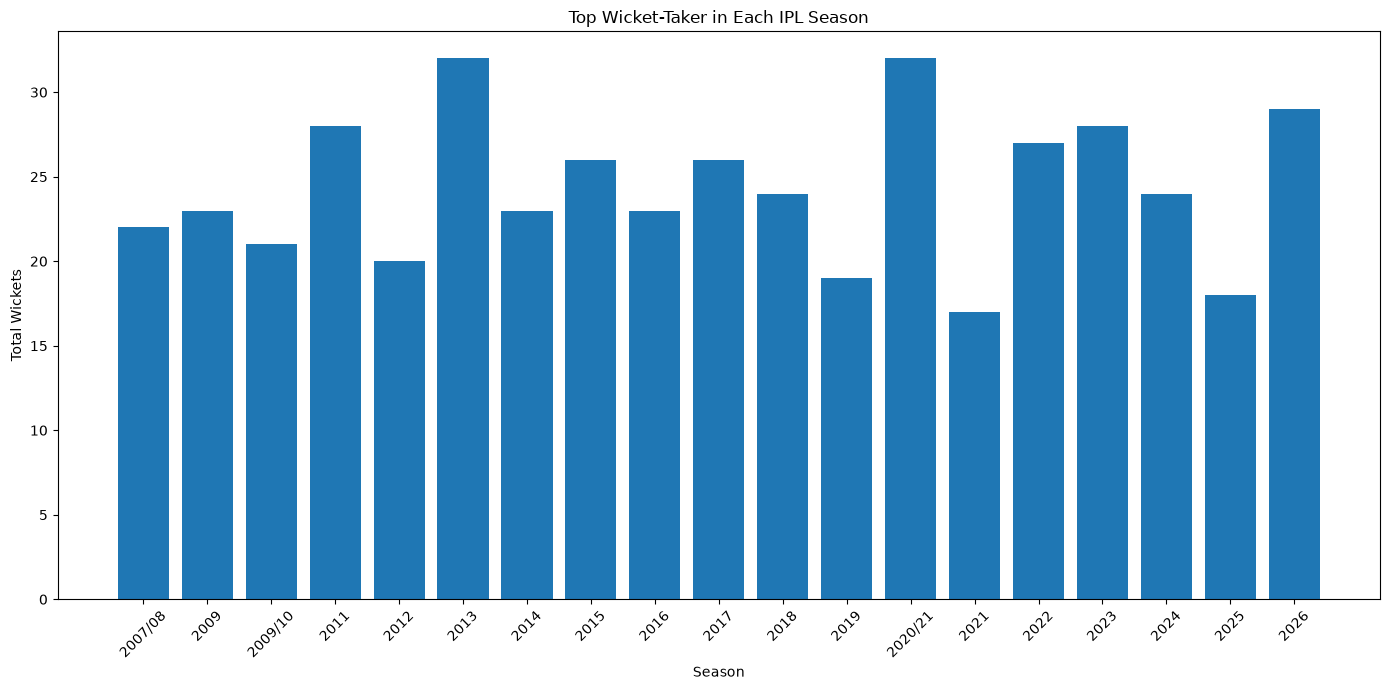

In [9]:
plt.figure(figsize=(14, 7))

plt.bar(
    top_bowler_by_season["season"].astype(str),
    top_bowler_by_season["wickets"]
)

plt.title("Top Wicket-Taker in Each IPL Season")
plt.xlabel("Season")
plt.ylabel("Total Wickets")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [10]:
# Counting the different types of dismissals
dismissal_stats = (
    df["wicket_types"]
    if "wicket_types" in df.columns
    else None
)

if dismissal_stats is None:
    dismissal_stats = pd.read_csv(
        os.path.join(data_path, "dismissal_stats.csv")
    )
else:
    dismissal_stats = (
        dismissal_stats.explode().dropna().value_counts().reset_index()
    )
    dismissal_stats.columns = ["dismissal_type", "count"]

dismissal_stats

,dismissal_type,count
0,caught,9321
1,bowled,2460
2,run out,1194
3,lbw,883
4,caught and bowled,410
5,stumped,388
6,hit wicket,20
7,retired hurt,19
8,retired out,6
9,obstructing the field,4


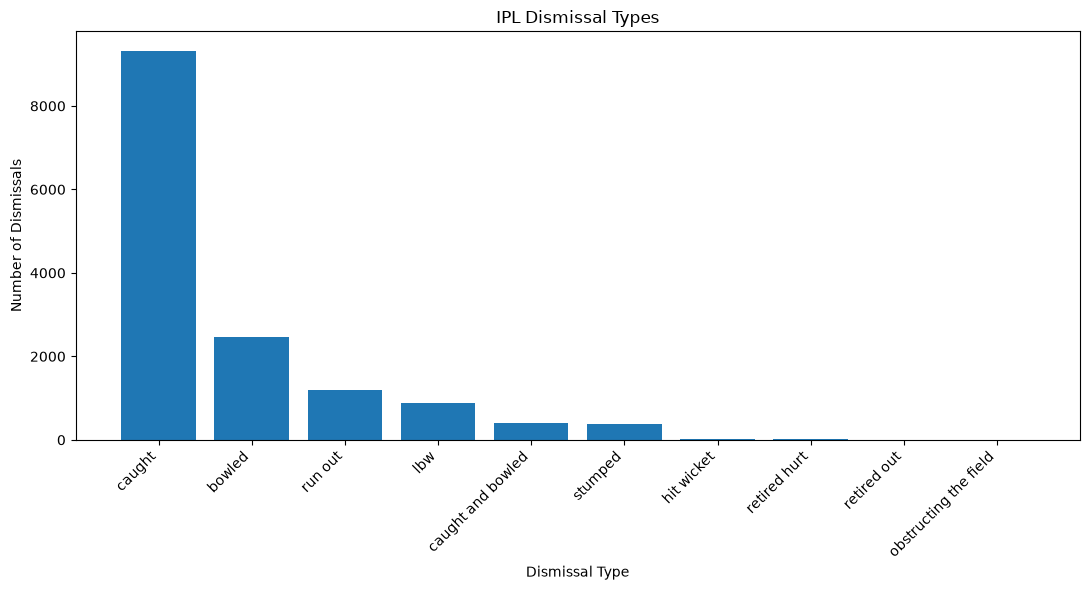

In [11]:
plt.figure(figsize=(11, 6))

plt.bar(
    dismissal_stats["dismissal_type"],
    dismissal_stats["count"]
)

plt.title("IPL Dismissal Types")
plt.xlabel("Dismissal Type")
plt.ylabel("Number of Dismissals")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [12]:
# Saving bowling results for future use
bowling_stats.to_csv(
    os.path.join(data_path, "bowling_stats.csv"),
    index=False
)

seasonal_bowling.to_csv(
    os.path.join(data_path, "seasonal_bowling.csv"),
    index=False
)

top_bowler_by_season.to_csv(
    os.path.join(data_path, "top_bowler_by_season.csv"),
    index=False
)

print("Bowling analysis datasets saved successfully!")

Bowling analysis datasets saved successfully!
